### **Ứng dụng Singular Value Decomposition (SVD) và Principal Component Analysis (PCA) trong phát hiện tin nhắn rác**

Notebook cài đặt từ đầu SVD và PCA bằng NumPy, kiểm chứng với `scikit-learn`, dùng chúng để giảm chiều biểu diễn TF-IDF của tin nhắn SMS trước một bộ phân loại logistic regression, và kiểm tra bằng số các kết quả lý thuyết (Eckart–Young, PCA là SVD của dữ liệu tâm hóa, vai trò của tâm hóa). Chứng minh đầy đủ nằm trong `slide/script.md`; các tham chiếu PHẦN x và công thức (y) trỏ đến file đó.

### **Bộ dữ liệu sử dụng**

SMS Spam Collection (UCI Machine Learning Repository): 5.574 tin nhắn SMS tiếng Anh gán nhãn `ham` (tin thường) hoặc `spam` (tin rác), khoảng 13% là spam. Văn bản ngắn, nhiều nhiễu và có nhiều tin spam cùng mẫu chỉ khác số điện thoại, nên việc làm sạch và loại trùng ảnh hưởng trực tiếp đến độ tin cậy của đánh giá.

In [1]:
import os
import re
import io
import html
import time
import zipfile
import platform
import urllib.request

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import matplotlib.pyplot as plt
import sklearn
from matplotlib.colors import LinearSegmentedColormap

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

NOTEBOOK_START = time.perf_counter()
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = os.path.join(os.getcwd(), "data")
DATA_PATH = os.path.join(DATA_DIR, "SMSSpamCollection")

COLORS = {
    "ham": "#2a78d6", "spam": "#eb6834",
    "lsa": "#2a78d6", "pca": "#eb6834", "baseline": "#1baf7a",
    "grid": "#e1e0d9", "axis": "#c3c2b7", "muted": "#898781",
}
plt.rcParams.update({
    "figure.dpi": 100, "figure.figsize": (8, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": COLORS["axis"], "axes.labelcolor": "#52514e",
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})
SEQUENTIAL_CMAP = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#2a78d6", "#0d366b"])
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 110)

### **Tải và đọc dữ liệu**

File được tải từ UCI, lỗi thì dùng bản sao trên GitHub; nếu đã có trong `data/` thì đọc trực tiếp. Bắt buộc dùng `quoting=3` (`csv.QUOTE_NONE`) vì nhiều tin chứa dấu nháy không khép.

In [2]:
UCI_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
MIRROR_URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"


def download_dataset(path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    try:
        with urllib.request.urlopen(UCI_URL, timeout=60) as resp:
            archive = zipfile.ZipFile(io.BytesIO(resp.read()))
        with archive.open("SMSSpamCollection") as src, open(path, "wb") as dst:
            dst.write(src.read())
        print("Downloaded from UCI.")
    except Exception as exc:
        print(f"UCI download failed ({exc}); using mirror.")
        with urllib.request.urlopen(MIRROR_URL, timeout=60) as resp, open(path, "wb") as dst:
            dst.write(resp.read())


if not os.path.exists(DATA_PATH):
    download_dataset(DATA_PATH)
raw = pd.read_csv(DATA_PATH, sep="\t", header=None, names=["label", "text"], quoting=3, encoding="utf-8")
raw["is_spam"] = (raw["label"] == "spam").astype(int)
print(raw.shape)
raw.head(3)

(5574, 3)


,label,text,is_spam
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore w...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry ques...,1


### **Mô tả dữ liệu**

Phân bố nhãn, độ dài tin nhắn theo lớp (trung bình, trung vị, lớn nhất) và hai tin mẫu mỗi lớp. Histogram dùng mật độ vì hai lớp có kích thước rất khác nhau.

label
ham     4827
spam     747 
spam share: 13.4%
      n_chars             n_words            
         mean median  max    mean median  max
label                                        
ham      71.5   52.0  910    14.3   11.0  171
spam    138.7  149.0  223    23.9   25.0   35

ham examples
   Dear,Me at cherthala.in case u r coming cochin pls call bfore u start.i shall also reach accordingly.or tell me which day u r coming.tmorow i am engaged ans its holiday.
   Ok. I only ask abt e movie. U wan ktv oso?

spam examples
   Summers finally here! Fancy a chat or flirt with sexy singles in yr area? To get MATCHED up just reply SUMMER now. Free 2 Join. OptOut txt STOP Help08714742804
   This is the 2nd time we have tried 2 contact u. U have won the 750 Pound prize. 2 claim is easy, call 08718726970 NOW! Only 10p per min. BT-national-rate 


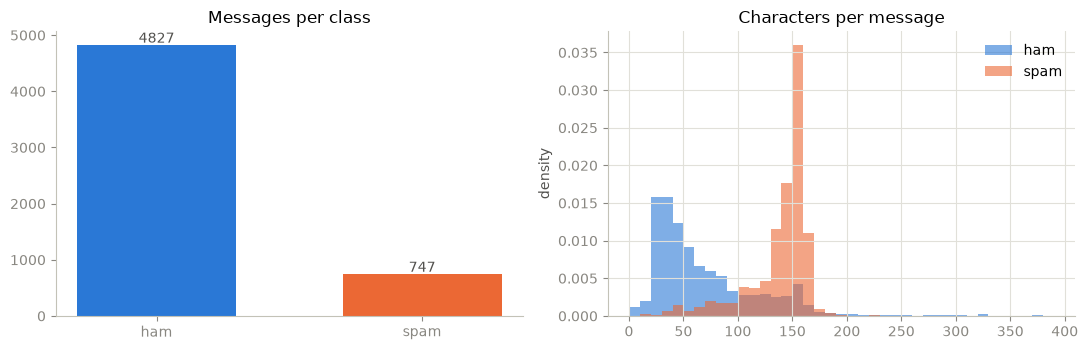

In [3]:
counts = raw["label"].value_counts()
print(counts.to_string(), f"\nspam share: {counts['spam'] / len(raw):.1%}")
raw["n_chars"] = raw["text"].str.len()
raw["n_words"] = raw["text"].str.split().str.len()
print(raw.groupby("label")[["n_chars", "n_words"]].agg(["mean", "median", "max"]).round(1).to_string())
for label in ["ham", "spam"]:
    print(f"\n{label} examples")
    for text in raw.loc[raw["label"] == label, "text"].sample(2, random_state=RANDOM_STATE):
        print("  ", text)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(counts.index, counts.values, color=[COLORS["ham"], COLORS["spam"]], width=0.6)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 40, str(v), ha="center", color="#52514e")
axes[0].set_title("Messages per class")
axes[0].grid(False)
for label in ["ham", "spam"]:
    axes[1].hist(raw.loc[raw["label"] == label, "n_chars"], bins=np.arange(0, 400, 10), density=True,
                 alpha=0.6, color=COLORS[label], label=label)
axes[1].set_title("Characters per message")
axes[1].set_ylabel("density")
axes[1].legend()
plt.tight_layout()
plt.show()

Tin spam dài hơn hẳn và tập trung sát giới hạn 160 ký tự của một SMS, trong khi ham phần lớn rất ngắn.

### **Tiền xử lý**

**Chuẩn hóa văn bản.** Số điện thoại, giá tiền hay mã ngắn cụ thể gần như không lặp lại, nhưng *sự có mặt* của chúng là tín hiệu spam mạnh. `normalize_text` thay chúng bằng token đại diện theo thứ tự cố định: `html.unescape` → chữ thường → email → URL → tiền → số điện thoại → số còn lại → bỏ ký tự không phải chữ cái. Email được xử lý trước URL vì nhánh `\S+\.(com|...)` của URL sẽ nuốt địa chỉ email. Số điện thoại là dãy ít nhất 5 chữ số, cho phép khoảng trắng hoặc gạch nối giữa các chữ số; ranh giới dùng lookaround thay cho `\b` vì dữ liệu có số dính chữ như `08452810075over18's`. Khối `assert` dưới đây cố định hành vi mong đợi.

In [4]:
EMAIL_RE = re.compile(r"\S+@\S+")
URL_RE = re.compile(r"(https?://\S+|www\.\S+|\b\S+\.(?:com|co\.uk|net|org)\b)")
MONEY_RE = re.compile(r"[£$€]\s*\d+(?:[.,]\d+)*|\b\d+(?:[.,]\d+)*\s*(?:p|pence|pounds?)\b")
PHONE_RE = re.compile(r"(?<!\d)\d(?:[ -]?\d){4,}(?!\d)")
NUMBER_RE = re.compile(r"\d+")
NON_ALPHA_RE = re.compile(r"[^a-z\s]")


def normalize_text(text):
    text = html.unescape(text).lower()
    text = EMAIL_RE.sub(" emailtoken ", text)
    text = URL_RE.sub(" urltoken ", text)
    text = MONEY_RE.sub(" moneytoken ", text)
    text = PHONE_RE.sub(" phonetoken ", text)
    text = NUMBER_RE.sub(" numtoken ", text)
    text = NON_ALPHA_RE.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()


EXPECTED = {
    "08452810075over18's": "phonetoken over numtoken s",
    "call 0800 123 4567 now": "call phonetoken now",
    "text WIN to 87121": "text win to phonetoken",
    "0800-123-4567 ok": "phonetoken ok",
    "Call 08704439680Ts&Cs apply": "call phonetoken ts cs apply",
    "£1000 prize": "moneytoken prize",
    "20,000 pounds txt": "moneytoken txt",
    "Cost 150p/day": "cost moneytoken day",
    "mail a@b.com": "mail emailtoken",
    "see www.textpod.net": "see urltoken",
    "on 21st May 2005": "on numtoken st may numtoken",
    "I am  &lt;#&gt;  inches": "i am inches",
}
for source, expected in EXPECTED.items():
    assert normalize_text(source) == expected, (source, normalize_text(source))
print(f"all {len(EXPECTED)} normalisation checks passed\n")

for text in [raw.loc[raw["label"] == "ham", "text"].iloc[6], raw.loc[raw["label"] == "spam", "text"].iloc[0]]:
    print(text, "\n  ->", normalize_text(text))

all 12 normalisation checks passed

I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today. 
  -> i m gonna be home soon and i don t want to talk about this stuff anymore tonight k i ve cried enough today
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's 
  -> free entry in numtoken a wkly comp to win fa cup final tkts numtoken st may numtoken text fa to phonetoken to receive entry question std txt rate t c s apply phonetoken over numtoken s


**Làm sạch và chia tập.** Loại trùng phải làm trên văn bản đã chuẩn hóa, không phải văn bản gốc: nhiều tin spam cùng mẫu chỉ khác số điện thoại sẽ trở thành một chuỗi `clean` giống hệt nhau, và nếu chúng rơi vào cả hai phía của phép chia thì điểm kiểm tra bị lạc quan. Thứ tự các bước:

1. chuẩn hóa toàn bộ, bỏ dòng có `clean` rỗng;
2. loại cả nhóm `clean` mang nhiều hơn một nhãn (phải làm trước khi loại trùng, nếu không nhãn mâu thuẫn sẽ bị mất dấu);
3. loại trùng theo `clean`;
4. chia train/test 80/20, rồi train thành sub-train/validation 75/25, phân tầng theo nhãn.

Validation dùng để chọn số thành phần $k$; tập test chỉ được dùng một lần ở cuối.

In [5]:
data = raw[["label", "text", "is_spam"]].copy()
data["clean"] = data["text"].map(normalize_text)

empty = data["clean"].eq("")
print(f"rows with empty clean text: {int(empty.sum())} removed")
data = data[~empty]

labels_per_text = data.groupby("clean")["label"].transform("nunique")
conflict = labels_per_text.gt(1)
print(f"clean texts with conflicting labels: {data.loc[conflict, 'clean'].nunique()} groups, "
      f"{int(conflict.sum())} rows removed")
data = data[~conflict]

rows_before = len(data)
data = data.drop_duplicates(subset="clean").reset_index(drop=True)
print(f"duplicate clean texts removed: {rows_before - len(data)}, remaining: {len(data)}")
print(data["label"].value_counts().to_string())

train_df, test_df = train_test_split(data, test_size=0.20, stratify=data["is_spam"], random_state=RANDOM_STATE)
sub_df, val_df = train_test_split(train_df, test_size=0.25, stratify=train_df["is_spam"],
                                  random_state=RANDOM_STATE)
assert set(test_df["clean"]).isdisjoint(train_df["clean"])
assert set(val_df["clean"]).isdisjoint(sub_df["clean"])
for name, part in [("train", train_df), ("  sub-train", sub_df), ("  validation", val_df), ("test", test_df)]:
    print(f"{name:14s} {len(part):5d} messages, {int(part['is_spam'].sum()):4d} spam")

y_train, y_test = train_df["is_spam"].to_numpy(), test_df["is_spam"].to_numpy()
y_sub, y_val = sub_df["is_spam"].to_numpy(), val_df["is_spam"].to_numpy()

rows with empty clean text: 2 removed
clean texts with conflicting labels: 0 groups, 0 rows removed
duplicate clean texts removed: 476, remaining: 5096
label
ham     4500
spam     596


train           4076 messages,  477 spam
  sub-train     3057 messages,  358 spam
  validation    1019 messages,  119 spam
test            1020 messages,  119 spam


**TF-IDF.** Mỗi tin là một hàng của $X \in \mathbb{R}^{n \times d}$, các cột là unigram và bigram. Với `sublinear_tf=True` và idf làm trơn mặc định, trọng số của từ $t$ trong tài liệu $i$ là (công thức (25))

$$
x_{it} = (1 + \log \mathrm{tf}_{it}) \cdot \big(\log\frac{1+n}{1+\mathrm{df}_t} + 1\big),
$$

sau đó chuẩn hóa $\ell_2$ từng hàng. Từ xuất hiện trong ít hơn hai tài liệu và stop word tiếng Anh bị loại. Bộ vector hóa chỉ fit trên train; một bộ thứ hai fit riêng trên sub-train phục vụ bước chọn $k$, để validation không ảnh hưởng đến từ điển hay idf.

In [6]:
def make_vectorizer():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")


vectorizer = make_vectorizer().fit(train_df["clean"])
X_train = vectorizer.transform(train_df["clean"]).tocsr()
X_test = vectorizer.transform(test_df["clean"]).tocsr()

vectorizer_sub = make_vectorizer().fit(sub_df["clean"])
X_sub = vectorizer_sub.transform(sub_df["clean"]).tocsr()
X_val = vectorizer_sub.transform(val_df["clean"]).tocsr()

vocab = np.array(vectorizer.get_feature_names_out())
n_docs, n_terms = X_train.shape
dense_bytes = n_docs * n_terms * 8
sparse_bytes = X_train.data.nbytes + X_train.indices.nbytes + X_train.indptr.nbytes
print(f"X_train: {X_train.shape}, non-zeros: {X_train.nnz}, density: {X_train.nnz / (n_docs * n_terms):.4%}")
print(f"X_test : {X_test.shape}")
print(f"X_sub  : {X_sub.shape}, X_val: {X_val.shape} (vocabulary fitted on sub-train)")
print(f"dense storage: {dense_bytes / 2**20:.1f} MiB, CSR storage: {sparse_bytes / 2**20:.2f} MiB")
for name, X in [("X_train", X_train), ("X_sub", X_sub)]:
    print(f"empty rows in {name} after TF-IDF (stop words, min_df=2): {int(np.sum(np.diff(X.indptr) == 0))}")

X_train: (4076, 5445), non-zeros: 36065, density: 0.1625%
X_test : (1020, 5445)
X_sub  : (3057, 4204), X_val: (1019, 4204) (vocabulary fitted on sub-train)
dense storage: 169.3 MiB, CSR storage: 0.43 MiB
empty rows in X_train after TF-IDF (stop words, min_df=2): 45
empty rows in X_sub after TF-IDF (stop words, min_df=2): 39


### **Cài đặt SVD và PCA từ đầu**

**SVD qua trị riêng của $A^\mathsf{T}A$.** Chứng minh xây dựng của Định lý 1 (PHẦN 1) là một thuật toán: chéo hóa trực giao $A^\mathsf{T}A$ (đối xứng, nửa xác định dương), đặt $\sigma_i = \sqrt{\lambda_i}$ và $u_i = Av_i/\sigma_i$. Khi $n \gt m$ thì áp dụng cho $A^\mathsf{T}$ để chéo hóa ma trận nhỏ hơn. Trị riêng của $A^\mathsf{T}A$ có sai số tuyệt đối cỡ $\lambda_1\varepsilon$, nên hạng số học được xác định bằng ngưỡng $\lambda_i \gt \lambda_1 \max(m,n)\varepsilon$.

In [7]:
def svd_via_eig(A):
    """Compact SVD of a dense matrix via the eigendecomposition of A^T A (or A A^T)."""
    A = np.asarray(A, dtype=float)
    m, n = A.shape
    if n > m:                                   # diagonalise the smaller Gram matrix
        U, s, Vt = svd_via_eig(A.T)
        return Vt.T, s, U.T
    lam, V = np.linalg.eigh(A.T @ A)
    order = np.argsort(lam)[::-1]
    lam, V = lam[order], V[:, order]
    r = int(np.sum(lam > lam[0] * max(m, n) * np.finfo(float).eps))
    s = np.sqrt(lam[:r])
    U = (A @ V[:, :r]) / s                      # u_i = A v_i / sigma_i
    return U, s, V[:, :r].T


def check_svd(A, U, s, Vt):
    s_ref = np.linalg.svd(A, compute_uv=False)
    r = len(s)
    return {
        "shape": A.shape, "rank": r,
        "max |sigma - sigma_np| / sigma_1": f"{np.max(np.abs(s - s_ref[:r])) / s_ref[0]:.2e}",
        "||A - U S Vt||_F / ||A||_F": f"{np.linalg.norm(A - (U * s) @ Vt) / np.linalg.norm(A):.2e}",
        "||U^T U - I||_F": f"{np.linalg.norm(U.T @ U - np.eye(r)):.2e}",
        "||V^T V - I||_F": f"{np.linalg.norm(Vt @ Vt.T - np.eye(r)):.2e}",
    }


rng = np.random.default_rng(RANDOM_STATE)
test_matrices = {
    "gaussian 200 x 60": rng.standard_normal((200, 60)),
    "rank 5, 150 x 80": rng.standard_normal((150, 5)) @ rng.standard_normal((5, 80)),
    "TF-IDF block 300 x d": X_train[:300].toarray(),
}
pd.DataFrame({name: check_svd(A, *svd_via_eig(A)) for name, A in test_matrices.items()}).T

,shape,rank,max |sigma - sigma_np| / sigma_1,||A - U S Vt||_F / ||A||_F,||U^T U - I||_F,||V^T V - I||_F
gaussian 200 x 60,"(200, 60)",60,9.78e-16,1.65e-15,1.73e-14,1.25e-14
"rank 5, 150 x 80","(150, 80)",5,5.29e-16,7.54e-16,1.44e-15,1.67e-15
TF-IDF block 300 x d,"(300, 5445)",296,1.26e-15,2.14e-15,3.71e-14,1.39e-13


**Toán tử thưa, tâm hóa ngầm và randomized SVD.** Các thuật toán bên dưới chỉ chạm vào ma trận qua `matmat` ($AM$), `rmatmat` ($A^\mathsf{T}M$) và `gram` ($AA^\mathsf{T}$). Với PCA, toán tử $X - \mathbf{1}\mu^\mathsf{T}$ được áp dụng mà không tạo ma trận đặc nhờ công thức (28), và ma trận Gram tâm hóa có dạng đóng (29): $X_cX_c^\mathsf{T} = XX^\mathsf{T} - (X\mu)\mathbf{1}^\mathsf{T} - \mathbf{1}(X\mu)^\mathsf{T} + \Vert\mu\Vert^2\mathbf{1}\mathbf{1}^\mathsf{T}$.

`randomized_svd` là thuật toán Halko–Martinsson–Tropp (PHẦN 4.5): ma trận Gauss $\Omega$ với $\ell = k + p$ cột, $Q = \mathrm{qr}(A\Omega)$, $q$ vòng power iteration có QR, rồi SVD của $B = Q^\mathsf{T}A$. Mặc định $p = k$, $q = 10$.

In [8]:
class SparseOperator:
    """matmat / rmatmat / gram interface for a sparse or dense matrix."""

    def __init__(self, X):
        self.X = X
        self.shape = X.shape

    def matmat(self, M):
        return np.asarray(self.X @ M)

    def rmatmat(self, M):
        return np.asarray(self.X.T @ M)

    def gram(self):                                       # X X^T, n x n
        G = self.X @ self.X.T
        return G.toarray() if sp.issparse(G) else np.asarray(G)


class CenteredOperator:
    """The operator X - 1 mu^T, applied without materialising the centred matrix."""

    def __init__(self, X, mean):
        self.X = X
        self.mean = np.asarray(mean, dtype=float).ravel()
        self.shape = X.shape

    def matmat(self, M):
        return np.asarray(self.X @ M) - np.outer(np.ones(self.shape[0]), self.mean @ M)

    def rmatmat(self, M):
        return np.asarray(self.X.T @ M) - np.outer(self.mean, np.asarray(M).sum(axis=0))

    def gram(self):                                       # eq. (29)
        x_mu = np.asarray(self.X @ self.mean).ravel()
        return SparseOperator(self.X).gram() - x_mu[:, None] - x_mu[None, :] + self.mean @ self.mean


def as_operator(A):
    return A if hasattr(A, "matmat") else SparseOperator(A)


def randomized_svd(A, k, n_oversamples=None, n_iter=10, random_state=None):
    """Rank-k approximate SVD (Halko, Martinsson, Tropp 2011) using only products with A and A^T."""
    A = as_operator(A)
    m, n = A.shape
    ell = min(k + (k if n_oversamples is None else n_oversamples), m, n)
    rng = np.random.default_rng(random_state)
    Q, _ = np.linalg.qr(A.matmat(rng.standard_normal((n, ell))))
    for _ in range(n_iter):
        Z, _ = np.linalg.qr(A.rmatmat(Q))
        Q, _ = np.linalg.qr(A.matmat(Z))
    U_small, s, Vt = np.linalg.svd(A.rmatmat(Q).T, full_matrices=False)
    return (Q @ U_small)[:, :k], s[:k], Vt[:k]

**Bộ đệm phân rã chính xác.** Vì $n \lt d$, phân rã chính xác rẻ nhất là chéo hóa ma trận Gram $n \times n$ (PHẦN 4.3): trị riêng cho toàn bộ phổ $\sigma_i$, vectơ riêng cho $U$, và $v_i = X^\mathsf{T}u_i/\sigma_i$. `exact_factors` làm việc này đúng một lần cho mỗi cặp (ma trận, chế độ tâm hóa), giữ toàn bộ phổ và $k_{\max} = 1000$ vectơ kỳ dị phải; mọi chỗ cần LSA/PCA chính xác về sau chỉ cắt `V_max[:, :k]`. Vì nghiệm $k$ thành phần đầu của SVD chính xác lồng nhau theo $k$, một lần phân rã cho nghiệm tối ưu tái tạo ở mọi $k \le k_{\max}$. Dấu của từng cặp $(u_i, v_i)$ được cố định sao cho phần tử lớn nhất về trị tuyệt đối của $u_i$ dương. Bộ đếm `EIGH_CALLS` xác nhận toàn notebook chỉ có bốn lần chéo hóa Gram: train và sub-train, mỗi ma trận hai chế độ.

**Các lớp giảm chiều.** `TruncatedSVDScratch` (Latent Semantic Analysis, không tâm hóa) và `PCAScratch` (tâm hóa) dùng chung `_SpectralReducer`. `fit(X, factors=...)` lấy nghiệm chính xác từ bộ đệm sau khi kiểm tra bộ đệm thuộc đúng ma trận, từ điển và chế độ tâm hóa; không có `factors` thì chạy `randomized_svd`. Quy ước phương sai theo `scikit-learn`: LSA dùng phương sai mẫu ddof = 0 của điểm chiếu chia cho tổng phương sai ddof = 0; PCA dùng $\sigma_i^2/(n-1)$ và tổng phương sai $\Vert X_c\Vert_F^2/(n-1)$ tính theo (18) mà không tâm hóa.

In [9]:
EIGH_CALLS = 0
K_MAX = 1000


class ExactFactors:
    """Full spectrum and the top-k_max singular vectors of X or of X - 1 mu^T."""

    def __init__(self, **fields):
        self.__dict__.update(fields)


def matrix_key(X):
    return (id(X), X.shape, X.nnz)


def exact_factors(X, center, k_max=K_MAX):
    global EIGH_CALLS
    t0 = time.perf_counter()
    n, d = X.shape
    mu = np.asarray(X.mean(axis=0)).ravel()
    op = CenteredOperator(X, mu) if center else SparseOperator(X)
    eigvals, U = np.linalg.eigh(op.gram())
    EIGH_CALLS += 1
    eigvals, U = eigvals[::-1], U[:, ::-1]
    numerical_rank = int(np.sum(eigvals > eigvals[0] * max(n, d) * np.finfo(float).eps))
    if k_max > numerical_rank:
        raise ValueError(f"k_max = {k_max} exceeds the numerical rank {numerical_rank}")
    U = U * np.sign(U[np.abs(U).argmax(axis=0), np.arange(n)])      # deterministic signs
    sigma = np.sqrt(np.clip(eigvals, 0.0, None))
    V_max = op.rmatmat(U[:, :k_max]) / sigma[:k_max]                 # v_i = A^T u_i / sigma_i
    return ExactFactors(center=center, mu=mu, eigvals=eigvals, sigma=sigma, numerical_rank=numerical_rank,
                        U=U, V_max=V_max, k_max=k_max, n_rows=n, fro_sq=float(X.multiply(X).sum()),
                        matrix_key=matrix_key(X), vocab_size=d, time=time.perf_counter() - t0)


F_train = exact_factors(X_train, center=False)
F_train_c = exact_factors(X_train, center=True)
for name, F in [("F_train (LSA)", F_train), ("F_train_c (PCA)", F_train_c)]:
    print(f"{name}: eigh of a {F.n_rows} x {F.n_rows} Gram matrix, numerical rank {F.numerical_rank}, "
          f"k_max = {F.k_max}, time {F.time:.1f} s")


class _SpectralReducer:
    """Rank-k projection x -> V_k^T x (LSA) or V_k^T (x - mu) (PCA)."""

    center = False

    def __init__(self, n_components, n_oversamples=None, n_iter=10, random_state=RANDOM_STATE):
        self.n_components = n_components
        self.n_oversamples = n_oversamples
        self.n_iter = n_iter
        self.random_state = random_state

    def fit(self, X, factors=None):
        n, k = X.shape[0], self.n_components
        if factors is not None:
            if (factors.matrix_key != matrix_key(X) or factors.vocab_size != X.shape[1]
                    or factors.center != self.center):
                raise ValueError("factors belong to a different matrix, vocabulary or centering mode")
            if k > factors.k_max:
                raise ValueError(f"n_components = {k} exceeds k_max = {factors.k_max}")
            self.mean_ = factors.mu
            self.components_ = factors.V_max[:, :k].T
            self.singular_values_ = factors.sigma[:k]
            scores = factors.U[:, :k] * factors.sigma[:k]
        else:
            self.mean_ = np.asarray(X.mean(axis=0)).ravel()
            op = CenteredOperator(X, self.mean_) if self.center else SparseOperator(X)
            U, s, Vt = randomized_svd(op, k, self.n_oversamples, self.n_iter, self.random_state)
            self.components_, self.singular_values_ = Vt, s
            scores = U * s
        sq_norm = X.multiply(X).sum() if sp.issparse(X) else np.sum(np.square(X))
        centred_sq = sq_norm - n * self.mean_ @ self.mean_                  # ||X_c||_F^2, eq. (18)
        if self.center:
            self.explained_variance_ = self.singular_values_ ** 2 / (n - 1)
            self.total_variance_ = centred_sq / (n - 1)
        else:
            self.explained_variance_ = scores.var(axis=0)                    # ddof = 0, as in scikit-learn
            self.total_variance_ = centred_sq / n
        self.explained_variance_ratio_ = self.explained_variance_ / self.total_variance_
        return self

    def transform(self, X):
        Z = np.asarray(X @ self.components_.T)
        return Z - self.mean_ @ self.components_.T if self.center else Z


class TruncatedSVDScratch(_SpectralReducer):
    center = False


class PCAScratch(_SpectralReducer):
    center = True

F_train (LSA): eigh of a 4076 x 4076 Gram matrix, numerical rank 3695, k_max = 1000, time 5.5 s
F_train_c (PCA): eigh of a 4076 x 4076 Gram matrix, numerical rank 3695, k_max = 1000, time 6.0 s


**Kiểm chứng tại $k = 50$.** Bảng thứ nhất so sánh 50 giá trị kỳ dị đầu của `randomized_svd` (ba cấu hình $p$, $q$) với nghiệm chính xác trong bộ đệm. Bảng thứ hai đối chiếu bốn mô hình tự cài đặt với `TruncatedSVD(algorithm="arpack")` và `PCA(svd_solver="arpack")`: sai số tương đối của $\sigma$, $|\cos|$ nhỏ nhất giữa các thành phần tương ứng (vectơ kỳ dị chỉ xác định sai khác dấu) và tổng tỉ lệ phương sai giải thích.

In [10]:
K_CHECK = 50
records = []
for p, q in [(10, 4), (50, 4), (50, 10)]:
    t0 = time.perf_counter()
    _, s, _ = randomized_svd(X_train, K_CHECK, n_oversamples=p, n_iter=q, random_state=RANDOM_STATE)
    rel = np.abs(s - F_train.sigma[:K_CHECK]) / F_train.sigma[:K_CHECK]
    records.append({"p": p, "q": q, "max rel. sigma error": f"{rel.max():.2e}", "at index i": int(rel.argmax()) + 1,
                    "mean rel. sigma error": f"{rel.mean():.2e}", "time (s)": round(time.perf_counter() - t0, 2)})
print(pd.DataFrame(records).to_string(index=False), "\n")

svd_ref = TruncatedSVD(K_CHECK, algorithm="arpack", random_state=RANDOM_STATE).fit(X_train)
pca_ref = PCA(K_CHECK, svd_solver="arpack", random_state=RANDOM_STATE).fit(X_train)
comparison = {}
for name, cls, ref, F in [("LSA", TruncatedSVDScratch, svd_ref, F_train), ("PCA", PCAScratch, pca_ref, F_train_c)]:
    for mode, factors in [("randomized", None), ("exact, cache", F)]:
        model = cls(K_CHECK).fit(X_train, factors=factors)
        cos = np.abs(np.sum(model.components_ * ref.components_, axis=1))
        comparison[f"{name} ({mode})"] = {
            "max rel. sigma error": f"{np.max(np.abs(model.singular_values_ - ref.singular_values_) / ref.singular_values_):.2e}",
            "min |cos|": round(cos.min(), 6),
            "sum EVR (ours)": round(model.explained_variance_ratio_.sum(), 5),
            "sum EVR (sklearn)": round(ref.explained_variance_ratio_.sum(), 5),
        }
print(pd.DataFrame(comparison).T.to_string(), "\n")

t0 = time.perf_counter()
_, s300, _ = randomized_svd(X_train, 300, random_state=RANDOM_STATE)
rand300_time = time.perf_counter() - t0
rel300 = np.abs(s300 - F_train.sigma[:300]) / F_train.sigma[:300]
print(f"randomized SVD at k = 300 (p = 300, q = 10): {rand300_time:.1f} s, max rel. sigma error {rel300.max():.1e}")
print(f"one exact_factors call (full spectrum + k_max = {K_MAX} vectors): {F_train.time:.1f} s")

 p  q max rel. sigma error  at index i mean rel. sigma error  time (s)
10  4             4.35e-02          50              1.22e-02      0.20
50  4             8.18e-03          47              2.29e-03      0.42
50 10             2.22e-04          49              1.79e-05      0.88 



                   max rel. sigma error min |cos| sum EVR (ours) sum EVR (sklearn)
LSA (randomized)               2.22e-04  0.998539        0.14598           0.14598
LSA (exact, cache)             1.96e-15       1.0        0.14598           0.14598
PCA (randomized)               2.61e-04  0.998911        0.14679            0.1468
PCA (exact, cache)             1.76e-15       1.0         0.1468            0.1468 



randomized SVD at k = 300 (p = 300, q = 10): 22.7 s, max rel. sigma error 4.2e-06
one exact_factors call (full spectrum + k_max = 1000 vectors): 5.5 s


Với $p = 10$, $q = 4$ (một mặc định phổ biến) sai số tương đối lớn nhất của $\sigma_i$ là $4{,}4 \cdot 10^{-2}$; tăng oversampling lên $p = 50$ giảm còn $8{,}2 \cdot 10^{-3}$, và thêm power iteration ($q = 10$) giảm còn $2{,}2 \cdot 10^{-4}$. Ở cả ba cấu hình, sai số lớn nhất rơi vào các chỉ số 47, 49 và 50 (cột `at index i`), tức các hướng gần ngưỡng cắt $k = 50$, những hướng khó tách nhất khỏi phần ngay dưới ngưỡng. Đó là lý do mặc định của đồ án là $p = k$, $q = 10$. Nghiệm chính xác từ bộ đệm khớp ARPACK đến cỡ $10^{-15}$ với $|\cos| = 1$, còn randomized SVD lệch dưới $3 \cdot 10^{-4}$ với $|\cos| \ge 0{,}9985$; tổng tỉ lệ phương sai giải thích trùng với scikit-learn đến chữ số thứ tư.

**Vai trò của randomized SVD.** Đây là thuật toán cho trường hợp $n$ quá lớn để chéo hóa Gram $n \times n$. Bước quét $k$ dùng một phân tích chính xác cố định để lấy nghiệm tối ưu tái tạo ở mọi $k$ (nghiệm $k$ thành phần đầu của SVD chính xác lồng nhau theo $k$); cắt một kết quả randomized tại $k_{\max}$ cũng cho các phép chiếu xấp xỉ hợp lệ và lồng nhau, nhưng là một thiết kế thí nghiệm khác, không tương đương với các lần randomized độc lập theo từng $k$ (oversampling $p = k$ phụ thuộc $k$). Trên bộ dữ liệu này $n \approx 4.000$ nên dùng nghiệm chính xác: một lần `exact_factors` (toàn phổ và 1000 vectơ) mất 5,5 s, còn một lần randomized SVD tại $k = 300$ mất 22,7 s.

### **Phổ giá trị kỳ dị**

Toàn bộ phổ của $X_\mathrm{train}$ lấy từ bộ đệm `F_train`. Kiểm tra đầu tiên là (8): $\sum_i \sigma_i^2 = \Vert X\Vert_F^2$; vì mỗi hàng TF-IDF có chuẩn 1, giá trị này bằng số hàng khác rỗng.

numerical rank: 3695
sum sigma_i^2 = 4031.000000, ||X||_F^2 = 4031.000000, non-empty rows = 4031
largest singular values: [6.5037 5.0664 4.5557 4.3308 4.0815]
k needed for 50%: 390, 70%: 828, 80%: 1172, 90%: 1694, 95%: 2122
energy kept by k = 50: 15.2%, 100: 23.6%, 300: 43.9%, 1000: 75.4%


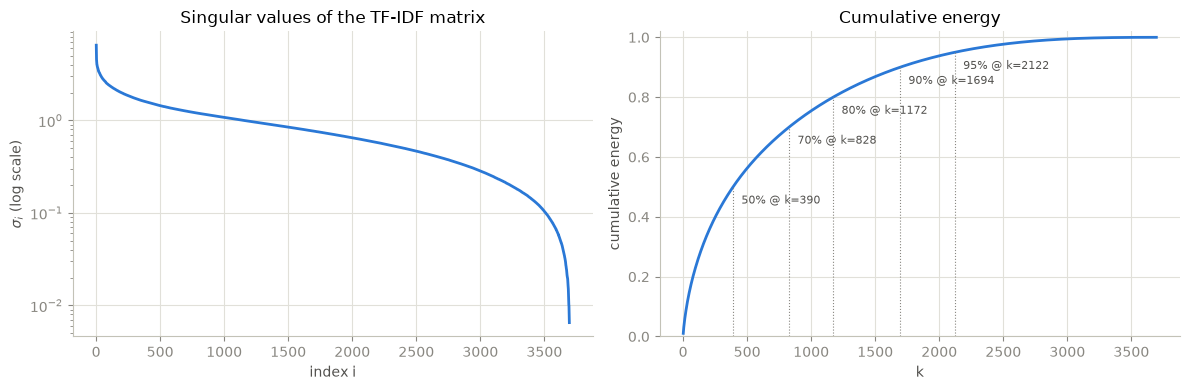

In [11]:
sigma = F_train.sigma
non_empty_rows = int(np.sum(np.diff(X_train.indptr) > 0))
assert np.isclose(sigma @ sigma, F_train.fro_sq, rtol=1e-9)
print(f"numerical rank: {F_train.numerical_rank}")
print(f"sum sigma_i^2 = {sigma @ sigma:.6f}, ||X||_F^2 = {F_train.fro_sq:.6f}, non-empty rows = {non_empty_rows}")
print("largest singular values:", np.round(sigma[:5], 4))
energy = np.cumsum(sigma ** 2) / np.sum(sigma ** 2)
k_for_energy = {q: int(np.searchsorted(energy, q) + 1) for q in [0.5, 0.7, 0.8, 0.9, 0.95]}
print("k needed for", ", ".join(f"{q:.0%}: {k}" for q, k in k_for_energy.items()))
print("energy kept by k =", ", ".join(f"{k}: {energy[k - 1]:.1%}" for k in [50, 100, 300, 1000]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
idx = np.arange(1, F_train.numerical_rank + 1)
axes[0].semilogy(idx, sigma[:F_train.numerical_rank], color=COLORS["lsa"])
axes[0].set_xlabel("index i")
axes[0].set_ylabel(r"$\sigma_i$ (log scale)")
axes[0].set_title("Singular values of the TF-IDF matrix")
axes[1].plot(idx, energy[:F_train.numerical_rank], color=COLORS["lsa"])
for q, k in k_for_energy.items():
    axes[1].plot([k, k], [0, q], color=COLORS["muted"], linewidth=0.8, linestyle=":")
    axes[1].annotate(f"{q:.0%} @ k={k}", (k, q), textcoords="offset points", xytext=(6, -12),
                     fontsize=8, color="#52514e")
axes[1].set_xlabel("k")
axes[1].set_ylabel("cumulative energy")
axes[1].set_title("Cumulative energy")
axes[1].set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

$\sum_i\sigma_i^2 = \Vert X\Vert_F^2 = 4031$, đúng bằng số hàng khác rỗng: 45 tin trở thành hàng rỗng sau TF-IDF vì mọi từ của chúng là stop word hoặc xuất hiện ở ít hơn hai tài liệu (`min_df=2`). Phổ suy giảm chậm, không có khuỷu rõ rệt: 50 thành phần giữ 15,2% năng lượng, 300 thành phần giữ 43,9%, 1000 thành phần giữ 75,4%, và cần 390 thành phần để đạt 50%. Đây là đặc điểm của văn bản thưa, nơi mỗi tài liệu đóng góp vài hướng gần như trực giao.

### **Trực quan hóa tin nhắn trong không gian 2 chiều**

Hai thành phần đầu của LSA và PCA trên tập huấn luyện, lấy trực tiếp từ bộ đệm ($U_2\Sigma_2$), tô màu theo nhãn.

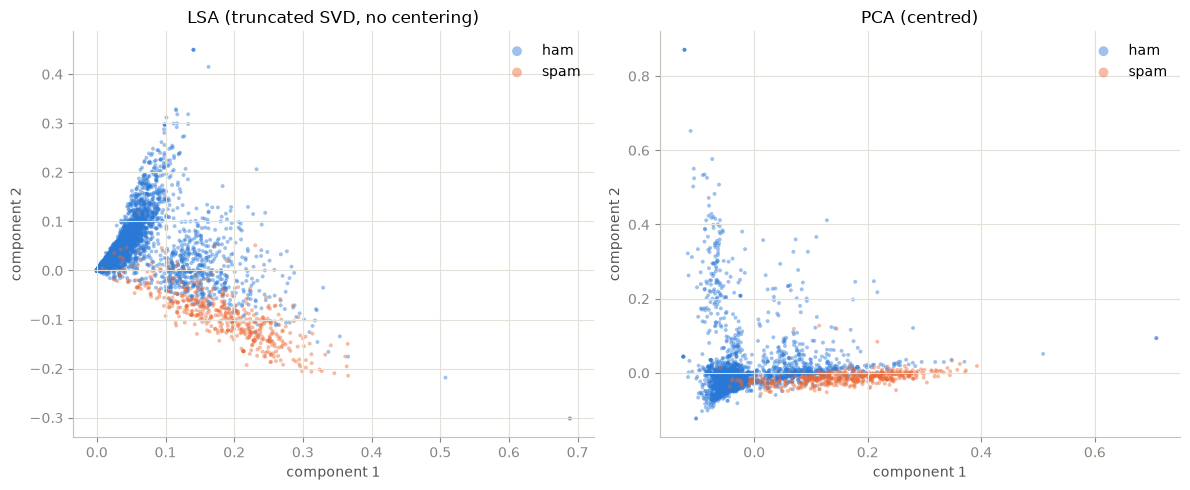

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, F, title in [(axes[0], F_train, "LSA (truncated SVD, no centering)"), (axes[1], F_train_c, "PCA (centred)")]:
    Z = F.U[:, :2] * F.sigma[:2]
    for label, name in [(0, "ham"), (1, "spam")]:
        mask = y_train == label
        ax.scatter(Z[mask, 0], Z[mask, 1], s=8, alpha=0.45, color=COLORS[name], label=name, edgecolors="none")
    ax.set_xlabel("component 1")
    ax.set_ylabel("component 2")
    ax.set_title(title)
    ax.legend(markerscale=2.5)
plt.tight_layout()
plt.show()

Hai thành phần chưa đủ để tách lớp, nhưng ở cả hai hình tin spam tập trung về một vùng. Ở hình LSA, tọa độ thứ nhất có cùng dấu với mọi tài liệu: $X$ không âm nên theo Perron–Frobenius có thể chọn $u_1, v_1$ không âm. Ở hình PCA, PC1 cực đại phương sai quanh trung bình nên điểm chiếu có trung bình 0 và trải về cả hai phía.

### **Diễn giải các thành phần**

Mỗi thành phần chính là một hướng $v_j$ trong không gian từ. Dấu được chọn sao cho điểm chiếu tương quan dương với nhãn spam; in 6 từ có trọng số dương lớn nhất và 6 từ âm lớn nhất của 3 PC đầu.

In [13]:
for j in range(3):
    scores = F_train_c.U[:, j] * F_train_c.sigma[j]
    corr = np.corrcoef(scores, y_train)[0, 1]
    v = np.sign(corr) * F_train_c.V_max[:, j]
    print(f"PC{j + 1}: corr(score, spam) = {abs(corr):+.3f}")
    print("   spam side:", ", ".join(f"{vocab[i]} ({v[i]:+.2f})" for i in np.argsort(v)[::-1][:6]))
    print("   ham side :", ", ".join(f"{vocab[i]} ({v[i]:+.2f})" for i in np.argsort(v)[:6]))

PC1: corr(score, spam) = +0.682
   spam side: numtoken (+0.74), phonetoken (+0.28), numtoken numtoken (+0.27), moneytoken (+0.21), free (+0.11), txt (+0.09)
   ham side : come (-0.10), ok (-0.10), know (-0.08), ll (-0.07), good (-0.06), home (-0.05)
PC2: corr(score, spam) = +0.065
   spam side: know (+0.11), just (+0.07), want (+0.06), good (+0.05), don (+0.05), love (+0.05)
   ham side : ok (-0.88), lor (-0.22), ok lor (-0.12), numtoken (-0.11), wat (-0.08), time (-0.08)
PC3: corr(score, spam) = +0.078
   spam side: know (+0.24), ok (+0.17), like (+0.09), did (+0.08), let (+0.06), dont (+0.06)
   ham side : come (-0.83), home (-0.20), going (-0.12), numtoken (-0.11), got (-0.10), time (-0.08)


PC1 có tương quan 0,68 với nhãn spam: phía dương là các token đại diện (`numtoken`, `phonetoken`, `moneytoken`) cùng *free*, *txt*; phía âm là từ hội thoại (*come*, *ok*, *know*). PC2 (*ok*, *lor*) và PC3 (*come*, *home*) gần như không tương quan với nhãn (0,07 và 0,08) và mô tả các nhóm tin ngắn trong hội thoại. PCA không nhìn vào nhãn; việc PC1 trùng với trục spam là quan sát trên bộ dữ liệu này.

### **Xây dựng mô hình**

Bộ phân loại giống nhau ở mọi thí nghiệm: logistic regression với $C = 1$, `class_weight="balanced"` và `max_iter=5000`, trên (a) TF-IDF đầy đủ (baseline), (b) điểm LSA $V_k^\mathsf{T}x$, (c) điểm PCA $V_k^\mathsf{T}(x - \mu)$. Không chuẩn hóa lại đặc trưng sau phép chiếu: $V_k$ có cột trực chuẩn nên phép chiếu giữ nguyên khoảng cách và góc trong không gian con, còn chuẩn hóa sẽ khuếch đại các tọa độ có phương sai nhỏ. `ReducedClassifier` đo riêng ba khoảng thời gian: phân rã (lấy từ bộ đệm), tạo đặc trưng $XV_k$ tại đúng $k$, và huấn luyện classifier.

In [14]:
def make_classifier():
    return LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000)


class ReducedClassifier:
    """Optional LSA / PCA reducer followed by logistic regression, with separate timings."""

    def __init__(self, reducer=None):
        self.reducer = reducer
        self.clf = make_classifier()

    def fit(self, X, y, factors=None):
        self.decomposition_time_ = self.feature_time_ = 0.0
        Z = X
        if self.reducer is not None:
            t0 = time.perf_counter()
            self.reducer.fit(X, factors=factors)
            self.decomposition_time_ = factors.time if factors is not None else time.perf_counter() - t0
            t0 = time.perf_counter()
            Z = self.reducer.transform(X)
            self.feature_time_ = time.perf_counter() - t0
        t0 = time.perf_counter()
        self.clf.fit(Z, y)
        self.clf_time_ = time.perf_counter() - t0
        self.total_time_ = self.decomposition_time_ + self.feature_time_ + self.clf_time_
        return self

    def _features(self, X):
        return X if self.reducer is None else self.reducer.transform(X)

    def predict(self, X):
        return self.clf.predict(self._features(X))

    def predict_proba(self, X):
        return self.clf.predict_proba(self._features(X))[:, 1]

### **Chọn số thành phần $k$**

Bộ đệm riêng của sub-train (`F_sub`, `F_sub_c`) được tạo một lần; đặc trưng của sub-train và validation tại $k_{\max}$ được chiếu một lần rồi cắt `[:, :k]`, nên trong vòng lặp chỉ còn huấn luyện classifier. Bộ đệm của train không bao giờ dùng cho sub-train hay validation.

Quy tắc chọn được cố định trước khi xem tập test: với mỗi phương pháp, chọn $k$ có F1 validation cao nhất (hòa thì $k$ nhỏ hơn); mô hình giảm chiều được chọn là phương pháp có F1 validation cao hơn tại $k$ của nó (hòa thì LSA). Cột thời gian trong bảng là thời gian huấn luyện classifier, sau khi đã có bộ đệm.

F_sub (LSA): numerical rank 2816, time 3.3 s
F_sub_c (PCA): numerical rank 2816, time 2.5 s
baseline (full TF-IDF, 4204 features): validation F1 = 0.9283



        val F1         classifier time (s)        
method     LSA     PCA                 LSA     PCA
k                                                 
2       0.7143  0.6993              0.0070  0.0068
10      0.8182  0.8482              0.0070  0.0082
50      0.8826  0.8755              0.0091  0.0060
100     0.8826  0.8826              0.0085  0.0092
300     0.9205  0.9205              0.0185  0.0223
1000    0.9205  0.9129              0.0401  0.0363

chosen k for LSA: 300 (validation F1 = 0.9205)
chosen k for PCA: 300 (validation F1 = 0.9205)
selected reduced model: LSA with k = 300


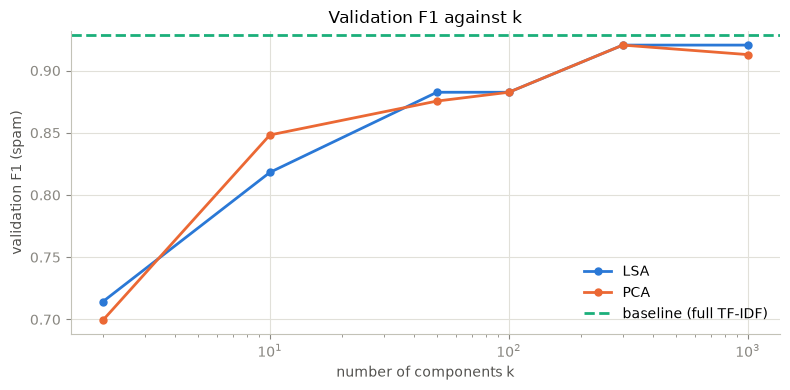

In [15]:
F_sub = exact_factors(X_sub, center=False)
F_sub_c = exact_factors(X_sub, center=True)
for name, F in [("F_sub (LSA)", F_sub), ("F_sub_c (PCA)", F_sub_c)]:
    print(f"{name}: numerical rank {F.numerical_rank}, time {F.time:.1f} s")

baseline_val = ReducedClassifier().fit(X_sub, y_sub)
baseline_val_f1 = f1_score(y_val, baseline_val.predict(X_val))
print(f"baseline (full TF-IDF, {X_sub.shape[1]} features): validation F1 = {baseline_val_f1:.4f}\n")

K_GRID = [2, 10, 50, 100, 300, 1000]
sweep_records = []
for method, F in [("LSA", F_sub), ("PCA", F_sub_c)]:
    shift = F.mu @ F.V_max if F.center else 0.0
    Z_sub_max = np.asarray(X_sub @ F.V_max) - shift
    Z_val_max = np.asarray(X_val @ F.V_max) - shift
    for k in K_GRID:
        clf = make_classifier()
        t0 = time.perf_counter()
        clf.fit(Z_sub_max[:, :k], y_sub)
        clf_time = time.perf_counter() - t0
        pred = clf.predict(Z_val_max[:, :k])
        sweep_records.append({"method": method, "k": k, "val F1": f1_score(y_val, pred),
                              "val precision": precision_score(y_val, pred),
                              "val recall": recall_score(y_val, pred), "classifier time (s)": clf_time})
sweep = pd.DataFrame(sweep_records)
print(sweep.pivot(index="k", columns="method", values=["val F1", "classifier time (s)"]).round(4).to_string())

best_k, best_f1 = {}, {}
for method in ["LSA", "PCA"]:
    top = sweep[sweep["method"] == method].sort_values(["val F1", "k"], ascending=[False, True]).iloc[0]
    best_k[method], best_f1[method] = int(top["k"]), float(top["val F1"])
    print(f"\nchosen k for {method}: {best_k[method]} (validation F1 = {best_f1[method]:.4f})", end="")
chosen = "LSA" if best_f1["LSA"] >= best_f1["PCA"] else "PCA"
print(f"\nselected reduced model: {chosen} with k = {best_k[chosen]}")

fig, ax = plt.subplots(figsize=(8, 4))
for method in ["LSA", "PCA"]:
    part = sweep[sweep["method"] == method]
    ax.plot(part["k"], part["val F1"], marker="o", markersize=5, color=COLORS[method.lower()], label=method)
ax.axhline(baseline_val_f1, color=COLORS["baseline"], linestyle="--", label="baseline (full TF-IDF)")
ax.set_xscale("log")
ax.set_xlabel("number of components k")
ax.set_ylabel("validation F1 (spam)")
ax.set_title("Validation F1 against k")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Baseline đạt F1 validation 0,9283. F1 của LSA tăng từ 0,7143 ($k = 2$) lên 0,8826 ($k = 50$) và 0,9205 ($k = 300$), không tăng thêm ở $k = 1000$; PCA cho kết quả tương tự (0,6993 ở $k = 2$, cao nhất 0,9205 ở $k = 300$). Theo quy tắc đã cố định, cả hai phương pháp chọn $k = 300$ và vì hòa nên mô hình giảm chiều được chọn là LSA. Không phương pháp nào vượt baseline trên validation. Khi đã có bộ đệm, huấn luyện classifier tại mỗi $k$ chỉ mất vài phần trăm giây.

### **Kiểm chứng lý thuyết bằng thực nghiệm**

**1. Eckart–Young (PHẦN 3).** Với $V$ có cột trực chuẩn, phần dư của phép chiếu tính được mà không tạo ma trận đặc nhờ đồng nhất thức (22): $\Vert X - XVV^\mathsf{T}\Vert_F^2 = \Vert X\Vert_F^2 - \Vert XV\Vert_F^2$. Bảng so sánh không gian con SVD (đo qua đồng nhất thức) với giá trị lý thuyết $\sum_{i\gt k}\sigma_i^2$ lấy từ toàn phổ, với một không gian con ngẫu nhiên và với không gian sinh bởi $k$ cột (từ) có chuẩn lớn nhất. Đồng nhất thức được đối chiếu với cách tính trực tiếp trên khối 300 hàng đầu.

In [16]:
def projection_residual(X, V):
    """||X - X V V^T||_F^2 = ||X||_F^2 - ||X V||_F^2 for V with orthonormal columns."""
    return float(X.multiply(X).sum()) - float(np.sum(np.square(np.asarray(X @ V))))


X_block = X_train[:300]
V_check = F_train.V_max[:, :50]
direct = float(np.sum(np.square(X_block.toarray() - (X_block @ V_check) @ V_check.T)))
via_identity = projection_residual(X_block, V_check)
assert np.isclose(direct, via_identity, rtol=1e-10, atol=1e-10 * X_block.multiply(X_block).sum())
print(f"300-row block, k = 50: direct {direct:.10f}, identity {via_identity:.10f}\n")

col_norm_sq = np.asarray(X_train.multiply(X_train).sum(axis=0)).ravel()
rng = np.random.default_rng(RANDOM_STATE)
ey_records = []
for k in [10, 50, 100, 300, 1000]:
    Q_random, _ = np.linalg.qr(rng.standard_normal((n_terms, k)))
    measured = projection_residual(X_train, F_train.V_max[:, :k])
    theory = float(np.sum(sigma[k:] ** 2))
    ey_records.append({"k": k, "SVD (measured)": measured, "sum_{i>k} sigma_i^2": theory,
                       "random subspace": projection_residual(X_train, Q_random),
                       "top-k columns": F_train.fro_sq - float(np.sort(col_norm_sq)[::-1][:k].sum()),
                       "|SVD - theory|": f"{abs(measured - theory):.1e}"})
pd.DataFrame(ey_records).set_index("k").round(3)

300-row block, k = 50: direct 252.9815647647, identity 252.9815647647



,SVD (measured),sum_{i>k} sigma_i^2,random subspace,top-k columns,|SVD - theory|
k,,,,,
10,3830.643,3830.643,4023.636,3872.692,0.0e+00
50,3418.941,3418.941,3993.979,3511.654,4.5e-13
100,3081.613,3081.613,3957.264,3221.960,4.5e-13
300,2262.960,2262.960,3808.651,2555.561,4.5e-13
1000,990.246,990.246,3292.609,1529.777,6.8e-13


Đồng nhất thức (22) khớp với cách tính trực tiếp trên khối 300 hàng đến 10 chữ số. Phần dư đo được của không gian con SVD trùng với $\sum_{i\gt k}\sigma_i^2$ đến cỡ $10^{-12}$ ở mọi $k$, và luôn nhỏ hơn hai lựa chọn còn lại: tại $k = 1000$ là 990 so với 1530 khi giữ 1000 từ có chuẩn lớn nhất và 3293 với không gian con ngẫu nhiên. Định lý nói về sai số tái tạo theo chuẩn Frobenius, không nói về khả năng phân loại.

**2. PCA là SVD của dữ liệu tâm hóa (PHẦN 2).** Ba cách tính phương sai của 5 thành phần chính đầu: trị riêng của ma trận hiệp phương sai do `PCA(svd_solver="arpack")` của scikit-learn trả về, $\sigma_i^2/(n-1)$ từ bộ đệm Gram tâm hóa, và phương sai mẫu của điểm chiếu $Z = (X - \mathbf{1}\mu^\mathsf{T})V_{10}$ tính lại từ đầu. Sau đó kiểm tra $\mathrm{Cov}(Z)$ chéo (Mệnh đề 4) và $\mathrm{tr}(C)$ so với `total_variance_`.

In [17]:
V10 = F_train_c.V_max[:, :10]
Z10 = np.asarray(X_train @ V10) - F_train_c.mu @ V10
pca_table = pd.DataFrame({
    "eigenvalue of C (sklearn ARPACK)": pca_ref.explained_variance_[:5],
    "sigma_i^2 / (n-1) (Gram cache)": F_train_c.sigma[:5] ** 2 / (n_docs - 1),
    "Var(Z_i), ddof=1": Z10[:, :5].var(axis=0, ddof=1),
}, index=[f"PC{i + 1}" for i in range(5)])
pca_table["max abs difference"] = (pca_table.max(axis=1) - pca_table.min(axis=1)).map("{:.1e}".format)
print(pca_table.to_string(float_format=lambda v: f"{v:.8f}"))

cov_Z = np.cov(Z10, rowvar=False)
print(f"\nmax |off-diagonal| of Cov(Z): {np.abs(cov_Z - np.diag(np.diag(cov_Z))).max():.1e}")
trace_C = F_train_c.eigvals.clip(0).sum() / (n_docs - 1)
total_variance = PCAScratch(10).fit(X_train, factors=F_train_c).total_variance_
print(f"trace(C) from the full centred spectrum = {trace_C:.8f}, total_variance_ (eq. 18) = {total_variance:.8f}")
lam_x, lam_c = F_train.eigvals[:K_MAX + 1], F_train_c.eigvals[:K_MAX]
tol = 1e-10 * lam_x[0]
print("Cauchy interlacing lambda_i(X^T X) >= lambda_i(X_c^T X_c) >= lambda_{i+1}(X^T X), i <= 1000:",
      bool(np.all(lam_x[:-1] >= lam_c - tol) and np.all(lam_c >= lam_x[1:] - tol)))

     eigenvalue of C (sklearn ARPACK)  sigma_i^2 / (n-1) (Gram cache)  Var(Z_i), ddof=1 max abs difference
PC1                        0.00757111                      0.00757111        0.00757111            2.6e-17
PC2                        0.00527351                      0.00527351        0.00527351            4.3e-18
PC3                        0.00466184                      0.00466184        0.00466184            1.0e-17
PC4                        0.00415381                      0.00415381        0.00415381            5.2e-18
PC5                        0.00400602                      0.00400602        0.00400602            6.1e-18

max |off-diagonal| of Cov(Z): 3.8e-18
trace(C) from the full centred spectrum = 0.98226041, total_variance_ (eq. 18) = 0.98226041
Cauchy interlacing lambda_i(X^T X) >= lambda_i(X_c^T X_c) >= lambda_{i+1}(X^T X), i <= 1000: True


Ba cách tính phương sai, gồm cả ARPACK của scikit-learn là một thuật toán độc lập, khớp đến cỡ $10^{-17}$; hiệp phương sai của 10 điểm PCA đầu có phần tử ngoài đường chéo lớn nhất cỡ $10^{-18}$, và $\mathrm{tr}(C)$ tính từ toàn phổ trùng với `total_variance_` theo (18). Vì $X^\mathsf{T}X = X_c^\mathsf{T}X_c + n\mu\mu^\mathsf{T}$ là cập nhật hạng một (19), trị riêng của hai ma trận đan xen nhau (Cauchy interlacing), và phép kiểm tra in ra `True`.

**3. Tâm hóa và quan hệ giữa LSA và PCA (PHẦN 2.6).** Đo cosin giữa thành phần đầu và vectơ trung bình $\mu$, tỉ lệ tài liệu có cùng dấu trên thành phần đầu, và các góc chính giữa $\mathrm{span}(V_k)$ của LSA và PCA: với hai cơ sở trực chuẩn, các giá trị kỳ dị của $V_\mathrm{LSA}^\mathsf{T}V_\mathrm{PCA}$ là cosin của các góc chính, nên giá trị nhỏ nhất cho góc lớn nhất giữa hai không gian con.

In [18]:
mu_unit = F_train.mu / np.linalg.norm(F_train.mu)
same_sign = lambda s: max(np.mean(s >= 0), np.mean(s <= 0))
print(f"|cos(v1 LSA, mu)| = {abs(F_train.V_max[:, 0] @ mu_unit):.4f}")
print(f"|cos(v1 PCA, mu)| = {abs(F_train_c.V_max[:, 0] @ mu_unit):.4f}")
print(f"share of documents with the same sign on component 1: LSA {same_sign(F_train.U[:, 0]):.3f}, "
      f"PCA {same_sign(F_train_c.U[:, 0]):.3f}\n")
for k in [50, 300]:
    V_lsa, V_pca = F_train.V_max[:, :k], F_train_c.V_max[:, :k]
    for V in (V_lsa, V_pca):
        assert np.linalg.norm(V.T @ V - np.eye(k)) < 1e-10
    cosines = np.linalg.svd(V_lsa.T @ V_pca, compute_uv=False)
    min_cos = cosines.min()
    print(f"k = {k:3d}: min cos of principal angles = {min_cos:.4f}, "
          f"largest principal angle = {np.degrees(np.arccos(np.clip(min_cos, -1, 1))):.1f} degrees")

|cos(v1 LSA, mu)| = 0.8832
|cos(v1 PCA, mu)| = 0.3269
share of documents with the same sign on component 1: LSA 1.000, PCA 0.740

k =  50: min cos of principal angles = 0.3016, largest principal angle = 72.4 degrees
k = 300: min cos of principal angles = 0.5113, largest principal angle = 59.3 degrees


Thành phần đầu của LSA gần song song với trung bình ($|\cos| = 0{,}883$) và mọi tài liệu có cùng dấu trên nó. Sau tâm hóa, PC1 cực đại phương sai quanh trung bình; hàm mục tiêu không còn số hạng $(w^\mathsf{T}\mu)^2$ của tọa độ trung bình. Điều này không bảo đảm PC1 trực giao hay có cosin nhỏ với $\mu$: số đo là $|\cos| = 0{,}327$, và 74% tài liệu vẫn cùng dấu trên PC1.

Hai ma trận Gram khác nhau một số hạng hạng một, nhưng điều đó chỉ suy ra tính đan xen của trị riêng, không suy ra hai không gian con gần nhau. Góc chính lớn nhất giữa $\mathrm{span}(V_k)$ của LSA và PCA là 72,4° tại $k = 50$ và 59,3° tại $k = 300$: hai không gian con khác nhau rõ rệt. Việc hai mô hình cho cùng F1 tại $k = 300$ là quan sát thực nghiệm, không phải hệ quả của lý thuyết.

### **Đánh giá cuối cùng trên tập test**

Ba mô hình được fit lại trên toàn bộ train với $k$ đã chọn (LSA và PCA dùng bộ đệm `F_train`, `F_train_c`) và đánh giá đúng một lần trên test. Cột thời gian là thời gian huấn luyện gồm cả chuẩn bị bộ đệm $k_{\max} = 1000$: phân rã + tạo đặc trưng tại $k$ + huấn luyện classifier; đây không phải thời gian huấn luyện độc lập tại $k$.

In [19]:
final_models = {
    "Baseline (TF-IDF)": (ReducedClassifier(), None),
    f"LSA (k={best_k['LSA']})": (ReducedClassifier(TruncatedSVDScratch(best_k["LSA"])), F_train),
    f"PCA (k={best_k['PCA']})": (ReducedClassifier(PCAScratch(best_k["PCA"])), F_train_c),
}
results, test_pred, test_prob = {}, {}, {}
for name, (model, factors) in final_models.items():
    model.fit(X_train, y_train, factors=factors)
    test_pred[name], test_prob[name] = model.predict(X_test), model.predict_proba(X_test)
    results[name] = {
        "accuracy": accuracy_score(y_test, test_pred[name]),
        "precision": precision_score(y_test, test_pred[name]),
        "recall": recall_score(y_test, test_pred[name]),
        "F1": f1_score(y_test, test_pred[name]),
        "ROC-AUC": roc_auc_score(y_test, test_prob[name]),
        "features": X_train.shape[1] if model.reducer is None else model.reducer.n_components,
        "train time incl. k_max=1000 cache (s)": model.total_time_,
    }
    print(f"{name:18s} decomposition {model.decomposition_time_:5.2f} s + features {model.feature_time_:.3f} s "
          f"+ classifier {model.clf_time_:.3f} s")
results_table = pd.DataFrame(results).T
results_table["features"] = results_table["features"].astype(int)
results_table.round(4)

Baseline (TF-IDF)  decomposition  0.00 s + features 0.000 s + classifier 0.018 s


LSA (k=300)        decomposition  5.53 s + features 0.011 s + classifier 0.017 s
PCA (k=300)        decomposition  6.00 s + features 0.014 s + classifier 0.014 s


,accuracy,precision,recall,F1,ROC-AUC,features,train time incl. k_max=1000 cache (s)
Baseline (TF-IDF),0.9814,0.9237,0.9160,0.9198,0.9917,5445,0.0183
LSA (k=300),0.9784,0.8943,0.9244,0.9091,0.9864,300,5.5616
PCA (k=300),0.9784,0.8943,0.9244,0.9091,0.9862,300,6.0284


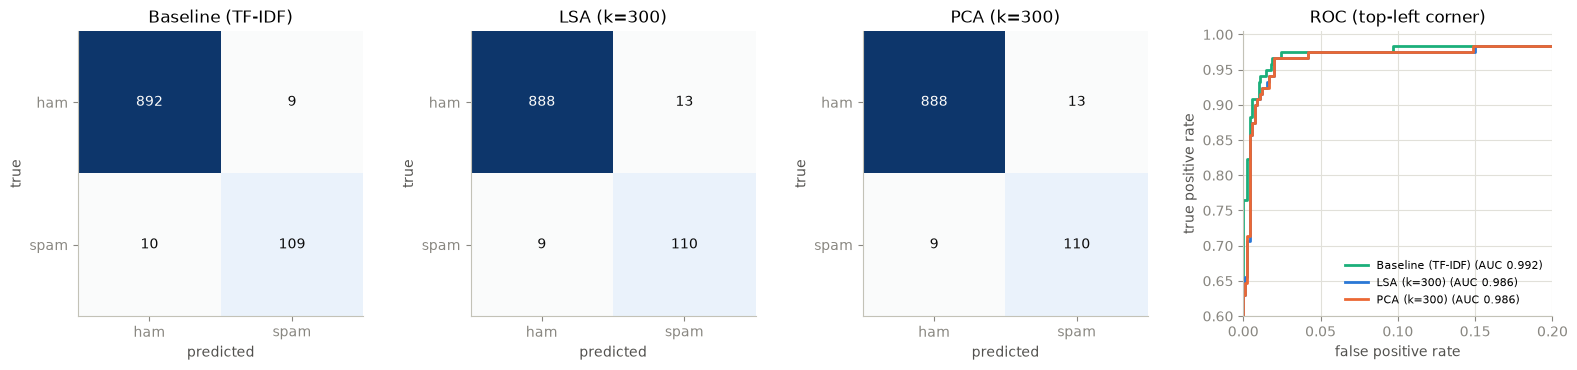

LSA (k=300): 22 errors, 16 of them also made by the baseline (19 baseline errors)
  true=ham  p(spam)=0.908 | Hi, Mobile no.  &lt;#&gt;  has added you in their contact list on www.fullonsms.com It s a great pla
  true=ham  p(spam)=0.527 | X2  &lt;#&gt; . Are you going to get that
  true=spam p(spam)=0.094 | Hello darling how are you today? I would love to have a chat, why dont you tell me what you look lik
  true=ham  p(spam)=0.567 | Sorry i'm not free...


In [20]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, pred) in zip(axes[:3], test_pred.items()):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap=SEQUENTIAL_CMAP, vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="#fcfcfb" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
    ax.set_xticks([0, 1], ["ham", "spam"])
    ax.set_yticks([0, 1], ["ham", "spam"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(name)
    ax.grid(False)
for (name, prob), color in zip(test_prob.items(), [COLORS["baseline"], COLORS["lsa"], COLORS["pca"]]):
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[3].plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(y_test, prob):.3f})")
axes[3].plot([0, 1], [0, 1], color=COLORS["muted"], linewidth=0.8, linestyle=":")
axes[3].set_xlim(0, 0.2)
axes[3].set_ylim(0.6, 1.005)
axes[3].set_xlabel("false positive rate")
axes[3].set_ylabel("true positive rate")
axes[3].set_title("ROC (top-left corner)")
axes[3].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

chosen_name = [name for name in final_models if name.startswith(chosen)][0]
wrong = np.flatnonzero(test_pred[chosen_name] != y_test)
wrong_baseline = set(np.flatnonzero(test_pred["Baseline (TF-IDF)"] != y_test))
print(f"{chosen_name}: {len(wrong)} errors, {len(set(wrong) & wrong_baseline)} of them also made by the baseline "
      f"({len(wrong_baseline)} baseline errors)")
for i in wrong[:4]:
    row = test_df.iloc[i]
    print(f"  true={row['label']:4s} p(spam)={test_prob[chosen_name][i]:.3f} | {row['text'][:100]}")

### **Thử mô hình với tin nhắn mới**

`predict_messages` chạy toàn bộ quy trình (chuẩn hóa, TF-IDF với từ điển của train, chiếu, logistic regression) trên văn bản tự do.

In [21]:
def predict_messages(messages):
    X_new = vectorizer.transform([normalize_text(m) for m in messages])
    table = pd.DataFrame({"message": messages})
    for name, (model, _) in final_models.items():
        table[f"p(spam) {name}"] = model.predict_proba(X_new).round(3)
    table[f"verdict ({chosen_name})"] = np.where(table[f"p(spam) {chosen_name}"] >= 0.5, "spam", "ham")
    return table


predict_messages([
    "Hey, are we still meeting at the library at 5? I'll bring the notes.",
    "Mum says dinner is at 7, can you pick up some bread on your way home?",
    "URGENT! You have won a £1000 cash prize. Call 09061234567 now to claim. T&Cs apply.",
    "Your mobile number has been selected for a free holiday. Reply YES or call 0800 123 4567.",
])

,message,p(spam) Baseline (TF-IDF),p(spam) LSA (k=300),p(spam) PCA (k=300),verdict (LSA (k=300))
0,"Hey, are we still meeting at the library at 5? I'll bring the notes.",0.094,0.121,0.120,ham
1,"Mum says dinner is at 7, can you pick up some bread on your way home?",0.072,0.080,0.080,ham
2,URGENT! You have won a £1000 cash prize. Call 09061234567 now to claim. T&Cs apply.,0.991,0.990,0.990,spam
3,Your mobile number has been selected for a free holiday. Reply YES or call 0800 123 4567.,0.947,0.969,0.968,spam


### **Kết luận**

**Lý thuyết.** Các kết quả trong `slide/script.md` được tái hiện bằng số trên ma trận TF-IDF $4076 \times 5445$: `svd_via_eig` khớp `numpy.linalg.svd` đến $10^{-15}$; nghiệm chính xác qua Gram khớp ARPACK đến $10^{-15}$, randomized SVD ($p = k$, $q = 10$) lệch dưới $3 \cdot 10^{-4}$; sai số chiếu đo qua (22) trùng $\sum_{i\gt k}\sigma_i^2$ đến $10^{-12}$; ba cách tính phương sai PCA khớp đến $10^{-17}$ và $\mathrm{Cov}(Z)$ chéo. Tâm hóa đổi tiêu chí chọn thành phần đầu ($|\cos(v_1, \mu)|$ từ 0,883 xuống 0,327) nhưng không làm PC1 trực giao với $\mu$.

**Phân loại.** Trên test (1.020 tin, 119 spam), baseline TF-IDF đạt accuracy 0,981, F1 0,920, ROC-AUC 0,992 (19 lỗi); LSA và PCA với $k = 300$ cùng đạt accuracy 0,978, F1 0,909 và ROC-AUC 0,986; mô hình được chọn (LSA) có 22 lỗi, 16 trong đó trùng với lỗi của baseline. Mô hình giảm chiều thấp hơn baseline một chút; chênh lệch này chưa được kiểm định thống kê. So với phiên bản trước của notebook (cả ba mô hình F1 0,939 với $k = 1000$), kết quả thay đổi do đồng thời việc loại rò rỉ dữ liệu (loại trùng theo văn bản đã chuẩn hóa, regex mới) và việc đổi từ randomized SVD sang nghiệm chính xác; không thể quy cho riêng một nguyên nhân. Lợi ích của giảm chiều ở đây là biểu diễn đặc 300 chiều, các trục diễn giải được và khả năng trực quan hóa, không phải độ chính xác.

**Hạn chế.** Mô hình tuyến tính trên bag-of-words, không nắm thứ tự từ hay ngữ nghĩa ngoài đồng xuất hiện; từ điển, idf, $\mu$ và $V_k$ gắn với tập huấn luyện nên phải tính lại khi từ vựng thay đổi; bộ dữ liệu nhỏ, một ngôn ngữ, tập test chỉ có 119 tin spam.

In [22]:
assert EIGH_CALLS == 4, EIGH_CALLS
print(f"Gram eigendecompositions in this notebook: {EIGH_CALLS}")
print(f"kernel time from the first cell to here: {time.perf_counter() - NOTEBOOK_START:.0f} s")
print(f"Python {platform.python_version()}, NumPy {np.__version__}, SciPy {scipy.__version__}, "
      f"scikit-learn {sklearn.__version__}, {platform.system()} {platform.release()}, {os.cpu_count()} logical CPUs, "
      f"{platform.processor()}")

Gram eigendecompositions in this notebook: 4
kernel time from the first cell to here: 51 s
Python 3.14.7, NumPy 2.5.4, SciPy 1.18.1, scikit-learn 1.9.1, Windows 11, 16 logical CPUs, AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD
